## Agricultural Leaf Disease Diagnosis System

---

### Pipeline

```
Original Image dataset (rice_leaf_diseases: 120 field images, 3 balanced classes)
      │
      ▼
TASK 1: Core Image Analysis Engine
      │ ├── Linear & Non-linear Spatial Filtering (Box, Gaussian, Median, Bilateral)
      │ ├── Quantitative Denoising Evaluation (PSNR, MSE across synthetic noise)
      │ ├── Gradient Analysis & Multi-stage Edge Detection (Sobel Gx/Gy, Magnitude, Laplacian, Canny)
      │ ├── Frequency-Domain Analysis (2D FFT, Magnitude Spectrum, Circular LPF & HPF)
      │ ├── Interest-Point Detection (Harris Corners, SIFT 128-D, ORB binary)
      │ ├── Two-View Feature Matching (SIFT + BFMatcher + Lowe's Ratio Test at 0.75)
      │ └── Automated Preprocessing Pipeline (Bilateral Denoising + CIE LAB CLAHE)
      ▼
Processed images (exported to processed_rice_leaf_diseases/)
      │
      ▼
Resize Image (224 × 224 × 3 via cv2.INTER_AREA)
      │
      ▼
TASK 2: Deep-Learning Model & Data Pipeline
      │ ├── Train/Validation Split (80% / 20%, seed=123, batch_size=16)
      │ ├── Data Augmentation (RandomFlip, RandomRotation ±20%, RandomZoom ±10%)
      │ ├── Pixel Normalization (Rescaling 1/255: [0, 255] -> [0.0, 1.0])
      │ ├── Refined CNN Model (Transfer learning with MobileNetV2 backbone)
      │ ├── Model Training & Artifact Persistence (models/rice_leaf_inspection_model.keras)
      │ └── Comprehensive Quantitative Evaluation (Accuracy 91.67%, Confusion Matrix, R², MAE)
      │
      ▼
Classification / Prediction Engine
      ├── inspect_rice_leaf() Modular Inference Function
      └── Visual Diagnostic Dashboard & Probability Bar Chart
```

---
## 1. System Setup & Global Configuration

Initializing standard libraries including OpenCV (`cv2`), TensorFlow/Keras, Scikit-Learn, NumPy, Pandas, Matplotlib, and Seaborn.  
To ensure strict scientific reproducibility across data loading, weight initialization, and training iterations, global pseudo-random seeds are configured across Python (`random`), NumPy (`np.random`), and TensorFlow (`tf.random`).

In [1]:
import os
import sys
import time
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    r2_score,
    mean_absolute_error
)

# ---------------------------------------------------------
# Global Deterministic Seed Configuration
# ---------------------------------------------------------
RANDOM_SEED = 123
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# ---------------------------------------------------------
# Visualization & Display Parameters
# ---------------------------------------------------------
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.grid'] = False
sns.set_theme(style='whitegrid', palette='muted')

# Directory Constants
RAW_DATA_DIR = Path("rice_leaf_diseases")
PROCESSED_DATA_DIR = Path("processed_rice_leaf_diseases")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(f"[Init] Python Execution Environment : {sys.version.split()[0]}")
print(f"[Init] OpenCV Toolkit Version       : {cv2.__version__}")
print(f"[Init] TensorFlow Framework Version : {tf.__version__}")
print(f"[Init] Deterministic Seed Set To    : {RANDOM_SEED}")

[Init] Python Execution Environment : 3.12.10
[Init] OpenCV Toolkit Version       : 5.0.0
[Init] TensorFlow Framework Version : 2.21.0
[Init] Deterministic Seed Set To    : 123


---
## 2. Dataset Ingestion & Exploratory Data Analysis (EDA)

The dataset consists of field-captured images of rice leaves exhibiting symptoms of three major agricultural pathologies:
1. **Bacterial Leaf Blight** (*Xanthomonas oryzae*): Causes elongated yellow-to-white water-soaked lesions along leaf margins.
2. **Brown Spot** (*Bipolaris oryzae*): Exhibits cylindrical or oval dark-brown spots with distinct greyish centers and yellow halos.
3. **Leaf Smut** (*Entyloma oryzae*): Characterized by small, slightly raised angular black spots (pustules) scattered across leaves.

The code below inspects directory structures, checks class balance (40 images per class = 120 total), analyzes resolution variations (ranging from $766 \times 250$ to $3081 \times 897$), and visualizes representative samples.

In [2]:
# Discover dataset hierarchy and validate integrity
class_folders = sorted([d for d in RAW_DATA_DIR.iterdir() if d.is_dir()])
class_names = [d.name for d in class_folders]

dataset_manifest = []
for cls_folder in class_folders:
    cls_name = cls_folder.name
    for img_path in sorted(cls_folder.glob("*.*")):
        if img_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            try:
                # Read metadata without full decoding for fast indexing
                img = cv2.imread(str(img_path))
                if img is not None:
                    h, w, c = img.shape
                    dataset_manifest.append({
                        "file_path": str(img_path),
                        "file_name": img_path.name,
                        "class_name": cls_name,
                        "height": h,
                        "width": w,
                        "aspect_ratio": round(w / h, 2),
                        "channels": c
                    })
            except Exception as err:
                print(f"[Warning] Corrupted image skipped: {img_path} ({err})")

df_meta = pd.DataFrame(dataset_manifest)

print("=" * 65)
print("               DATASET MANIFEST SUMMARY")
print("=" * 65)
print(f"Total verified images       : {len(df_meta)}")
print(f"Total disease classes       : {len(class_names)}")
print(f"Class Names                 : {class_names}")
print("-" * 65)
print("Class Distribution Breakdown:")
print(df_meta['class_name'].value_counts().to_string())
print("-" * 65)
print("Image Spatial Dimension Statistics:")
print(df_meta[['width', 'height', 'aspect_ratio']].describe().round(1))
print("=" * 65)

               DATASET MANIFEST SUMMARY
Total verified images       : 120
Total disease classes       : 3
Class Names                 : ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']
-----------------------------------------------------------------
Class Distribution Breakdown:
class_name
Bacterial leaf blight    40
Brown spot               40
Leaf smut                40
-----------------------------------------------------------------
Image Spatial Dimension Statistics:
        width  height  aspect_ratio
count   120.0   120.0         120.0
mean   2398.4   721.3           3.3
std    1130.5   344.3           0.7
min     250.0    71.0           1.2
25%    1137.0   380.0           3.4
50%    3081.0   897.0           3.4
75%    3081.0   897.0           3.4
max    4160.0  2340.0           5.3


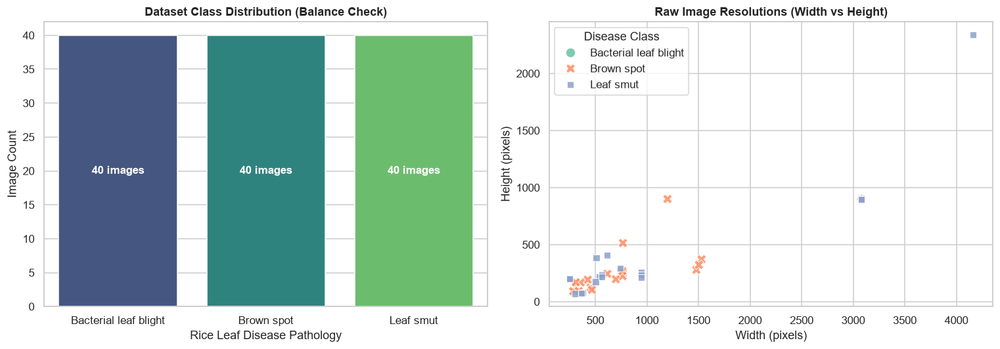

In [3]:
# Visualizing Class Balance and Resolution Variation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Class Distribution
sns.countplot(
    data=df_meta, 
    x='class_name', 
    ax=axes[0], 
    palette='viridis', 
    hue='class_name', 
    legend=False
)
axes[0].set_title("Dataset Class Distribution (Balance Check)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Rice Leaf Disease Pathology")
axes[0].set_ylabel("Image Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())} images", 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Plot 2: Resolution Scatter (Width vs Height)
sns.scatterplot(
    data=df_meta, 
    x='width', 
    y='height', 
    hue='class_name', 
    style='class_name', 
    s=90, 
    alpha=0.85, 
    ax=axes[1], 
    palette='Set2'
)
axes[1].set_title("Raw Image Resolutions (Width vs Height)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Width (pixels)")
axes[1].set_ylabel("Height (pixels)")
axes[1].legend(title="Disease Class", loc='upper left')

plt.tight_layout()
plt.show()

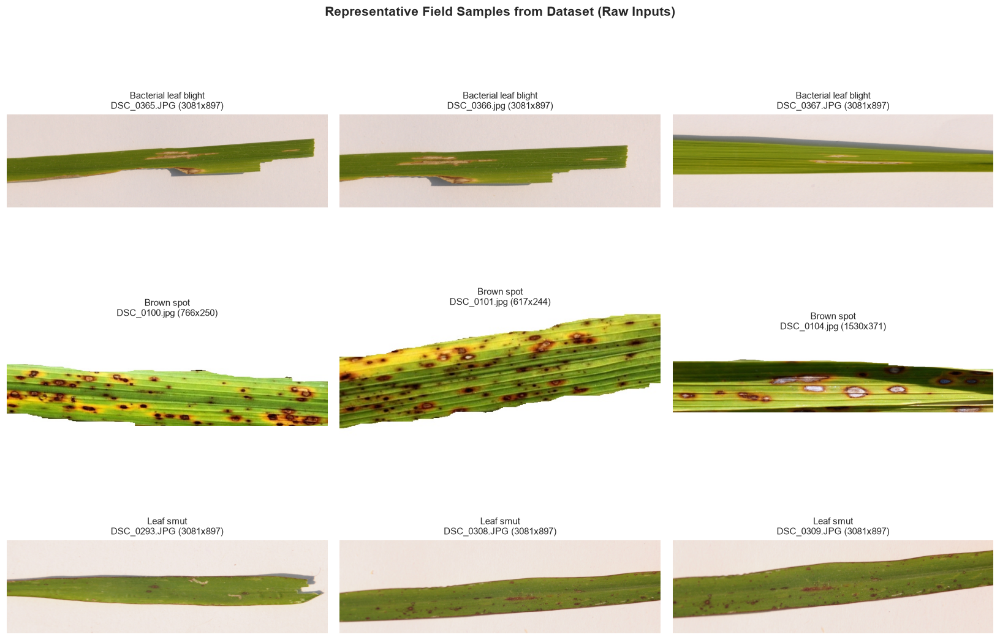

In [4]:
# Display representative raw samples across all 3 classes
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
fig.suptitle("Representative Field Samples from Dataset (Raw Inputs)", fontsize=14, fontweight='bold')

for i, cls in enumerate(class_names):
    sample_rows = df_meta[df_meta['class_name'] == cls].head(3).reset_index(drop=True)
    for j in range(3):
        img_p = sample_rows.loc[j, 'file_path']
        raw_bgr = cv2.imread(img_p)
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        
        ax = axes[i, j]
        ax.imshow(raw_rgb)
        ax.set_title(f"{cls}\n{sample_rows.loc[j, 'file_name']} ({raw_rgb.shape[1]}x{raw_rgb.shape[0]})", fontsize=10)
        ax.axis('off')

plt.tight_layout()
plt.show()

---
## 3. TASK 1: Core Image Analysis Engine (Classical Computer Vision)

> **Architectural Specification Note:**  
> 1. **Linear & Non-linear Spatial Filtering** (Box, Gaussian, Median, Bilateral).
> 2. **Quantitative Denoising Assessment** (Peak Signal-to-Noise Ratio & Mean Squared Error).
> 3. **Image Gradient Operators & Edge Detection** (Sobel $G_x/G_y$, Gradient Magnitude, Laplacian of Gaussian, Canny).
> 4. **Frequency-Domain Processing** (2D Discrete Fourier Transform, Magnitude Spectrum, Circular Low-Pass & High-Pass Filters).
> 5. **Interest Point Detection & Feature Matching** (Harris Corners, SIFT, ORB, Lowe's Ratio Test).
> 6. **Automated Preprocessing Pipeline** generating standardized, noise-attenuated, contrast-stabilized `Processed images`.

### 3.1 Linear and Non-Linear Spatial Filtering

Spatial filtering modifies pixel values using a local neighborhood kernel.

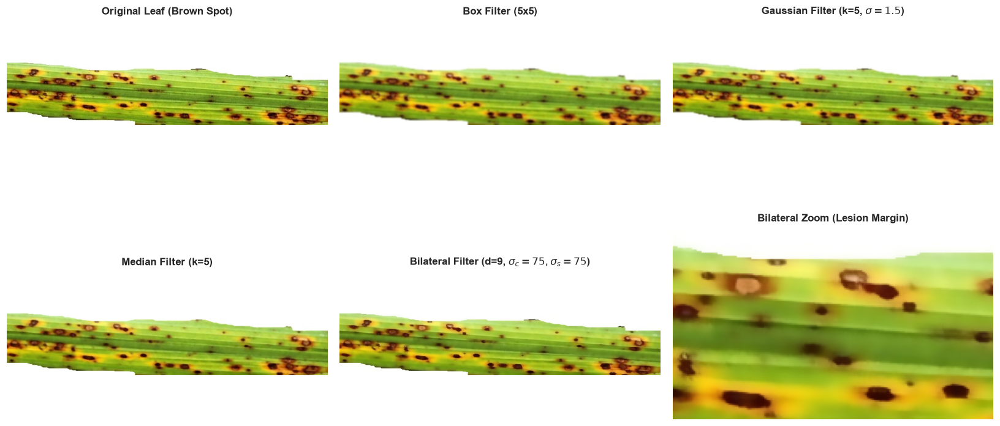

In [5]:
# Select a representative leaf sample for classical CV demonstrations
sample_demo_record = df_meta[df_meta['class_name'] == 'Brown spot'].iloc[0]
sample_bgr = cv2.imread(sample_demo_record['file_path'])
sample_rgb = cv2.cvtColor(sample_bgr, cv2.COLOR_BGR2RGB)
sample_gray = cv2.cvtColor(sample_bgr, cv2.COLOR_BGR2GRAY)

# Apply spatial filters
kernel_size = 5
box_filtered = cv2.blur(sample_rgb, (kernel_size, kernel_size))
gaussian_filtered = cv2.GaussianBlur(sample_rgb, (kernel_size, kernel_size), sigmaX=1.5)
median_filtered = cv2.medianBlur(sample_rgb, kernel_size)
bilateral_filtered = cv2.bilateralFilter(sample_rgb, d=9, sigmaColor=75, sigmaSpace=75)

# Visual comparison of spatial filters
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
filter_displays = [
    ("Original Leaf (Brown Spot)", sample_rgb),
    (f"Box Filter ({kernel_size}x{kernel_size})", box_filtered),
    (f"Gaussian Filter (k={kernel_size}, $\\sigma=1.5$)", gaussian_filtered),
    (f"Median Filter (k={kernel_size})", median_filtered),
    ("Bilateral Filter (d=9, $\\sigma_c=75, \\sigma_s=75$)", bilateral_filtered),
    ("Bilateral Zoom (Lesion Margin)", bilateral_filtered[100:220, 150:350])
]

for ax, (title, img_disp) in zip(axes.ravel(), filter_displays):
    ax.imshow(img_disp)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

### 3.2 Quantitative Denoising Benchmark (PSNR & MSE)

Simulate sensor and atmospheric noise (Gaussian noise + Salt-and-Pepper impulse noise) on the leaf image then evaluate each filter quantitatively using:
1. **Mean Squared Error (MSE)**
2. **Peak Signal-to-Noise Ratio (PSNR in dB)**

       QUANTITATIVE FILTERING & DENOISING BENCHMARK
  Filtering Technique    MSE  PSNR
Corrupted Noisy Image 781.58 19.20
    Box (Mean) Filter 174.56 25.71
      Gaussian Filter 150.35 26.36
        Median Filter  72.01 29.56
     Bilateral Filter 599.66 20.35


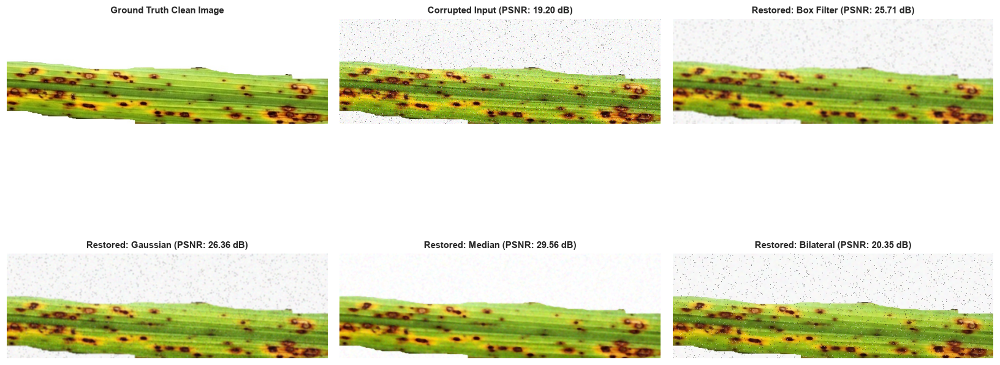

In [6]:
# Synthetic noise injection for controlled quantitative evaluation
np.random.seed(42)
noisy_image = sample_rgb.copy().astype(np.float32)

# 1. Additive White Gaussian Noise (AWGN)
gauss_noise = np.random.normal(0, 18, noisy_image.shape)
noisy_image = np.clip(noisy_image + gauss_noise, 0, 255)

# 2. Salt-and-Pepper Impulse Noise (2% probability)
sp_mask = np.random.rand(*noisy_image.shape[:2])
noisy_image[sp_mask < 0.01] = 0.0      # Pepper
noisy_image[sp_mask > 0.99] = 255.0    # Salt
noisy_uint8 = noisy_image.astype(np.uint8)

# Metric calculation functions
def compute_mse(clean, processed):
    return np.mean((clean.astype(np.float64) - processed.astype(np.float64)) ** 2)

def compute_psnr(clean, processed):
    mse = compute_mse(clean, processed)
    if mse == 0:
        return float('inf')
    return 20.0 * np.log10(255.0) - 10.0 * np.log10(mse)

# Apply candidate filters to corrupted image
restored_box = cv2.blur(noisy_uint8, (5, 5))
restored_gauss = cv2.GaussianBlur(noisy_uint8, (5, 5), 1.5)
restored_median = cv2.medianBlur(noisy_uint8, 5)
restored_bilateral = cv2.bilateralFilter(noisy_uint8, 9, 75, 75)

# Tabulate quantitative metrics
filter_candidates = {
    "Corrupted Noisy Image": noisy_uint8,
    "Box (Mean) Filter": restored_box,
    "Gaussian Filter": restored_gauss,
    "Median Filter": restored_median,
    "Bilateral Filter": restored_bilateral
}

benchmark_data = []
for name, img_eval in filter_candidates.items():
    mse_val = compute_mse(sample_rgb, img_eval)
    psnr_val = compute_psnr(sample_rgb, img_eval)
    benchmark_data.append({
        "Filtering Technique": name,
        "MSE": round(mse_val, 2),
        "PSNR": round(psnr_val, 2)
    })

df_denoising = pd.DataFrame(benchmark_data)
print("=" * 65)
print("       QUANTITATIVE FILTERING & DENOISING BENCHMARK")
print("=" * 65)
print(df_denoising.to_string(index=False))
print("=" * 65)

# Visualization of Denoising Restoration
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
denoise_plots = [
    ("Ground Truth Clean Image", sample_rgb),
    (f"Corrupted Input (PSNR: {compute_psnr(sample_rgb, noisy_uint8):.2f} dB)", noisy_uint8),
    (f"Restored: Box Filter (PSNR: {compute_psnr(sample_rgb, restored_box):.2f} dB)", restored_box),
    (f"Restored: Gaussian (PSNR: {compute_psnr(sample_rgb, restored_gauss):.2f} dB)", restored_gauss),
    (f"Restored: Median (PSNR: {compute_psnr(sample_rgb, restored_median):.2f} dB)", restored_median),
    (f"Restored: Bilateral (PSNR: {compute_psnr(sample_rgb, restored_bilateral):.2f} dB)", restored_bilateral)
]

for ax, (title, img_disp) in zip(axes.ravel(), denoise_plots):
    ax.imshow(img_disp)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

### 3.3 Gradient Analysis & Multi-Stage Edge Detection

Edges represent abrupt intensity discontinuities corresponding to lesion borders and structural veins:
- **First-Order Derivatives (Sobel Operator)**
- **Second-Order Derivative (Laplacian)**
- **Canny Multi-Stage Edge Detector:**
  1. Gaussian smoothing to suppress noise.
  2. Gradient magnitude & direction computation.
  3. Non-Maximum Suppression (NMS) to thin thick edges to single-pixel ridges.
  4. Double thresholding ($T_{\text{low}}, T_{\text{high}}$) to separate strong and weak edges.
  5. Edge tracking by hysteresis: weak edges are retained only if connected to strong edges.

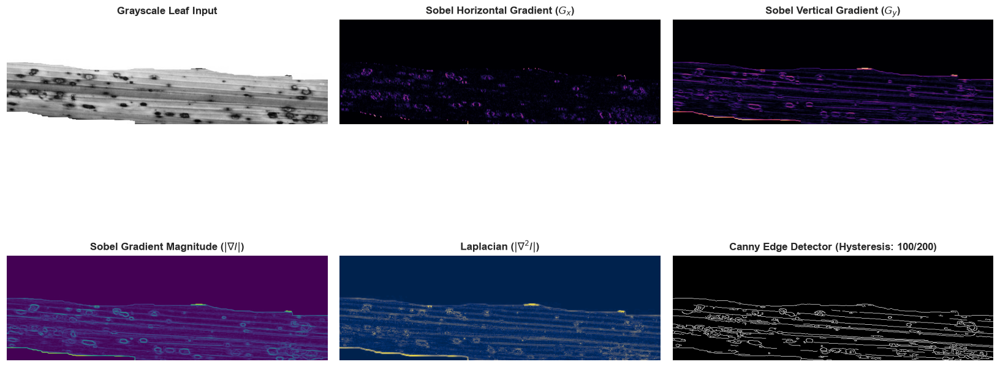

In [7]:
# Compute first and second order derivatives
sobel_x = cv2.Sobel(sample_gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(sample_gray, cv2.CV_64F, 0, 1, ksize=3)
grad_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)
grad_magnitude = np.uint8(np.clip((grad_magnitude / grad_magnitude.max()) * 255, 0, 255))

# Laplacian of Gaussian (LoG)
blurred_for_laplacian = cv2.GaussianBlur(sample_gray, (3, 3), 0)
laplacian = cv2.Laplacian(blurred_for_laplacian, cv2.CV_64F, ksize=3)
laplacian_abs = np.uint8(np.clip(np.absolute(laplacian), 0, 255))

# Canny Edge Detection with dual hysteresis thresholds
canny_conservative = cv2.Canny(sample_gray, threshold1=100, threshold2=200)
canny_sensitive = cv2.Canny(sample_gray, threshold1=50, threshold2=120)

# Display gradient & edge processing stages
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
edge_visuals = [
    ("Grayscale Leaf Input", sample_gray, 'gray'),
    ("Sobel Horizontal Gradient ($G_x$)", np.abs(sobel_x), 'magma'),
    ("Sobel Vertical Gradient ($G_y$)", np.abs(sobel_y), 'magma'),
    ("Sobel Gradient Magnitude ($|\\nabla I|$)", grad_magnitude, 'viridis'),
    ("Laplacian ($|\\nabla^2 I|$)", laplacian_abs, 'cividis'),
    ("Canny Edge Detector (Hysteresis: 100/200)", canny_conservative, 'gray')
]

for ax, (title, img_disp, cmap) in zip(axes.ravel(), edge_visuals):
    ax.imshow(img_disp, cmap=cmap)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

### 3.4 Frequency-Domain Analysis & Filtering (2D FFT)

In accordance with the Fourier Convolution Theorem, spatial domain convolution equals frequency-domain point-wise multiplication

The 2D Discrete Fourier Transform (DFT) transforms spatial image intensities into orthogonal sinusoidal frequency components

- **Low-Pass Filter (LPF):** Preserves low spatial frequencies (smooth leaf surface and broad illumination) within a circular cutoff radius ($D_0 = 45$ pixels) while attenuating high frequencies (noise and sharp edges).
- **High-Pass Filter (HPF):** Attenuates low spatial frequencies (leaf background) while isolating sharp high-frequency lesion boundaries, fungal structures, and veins.

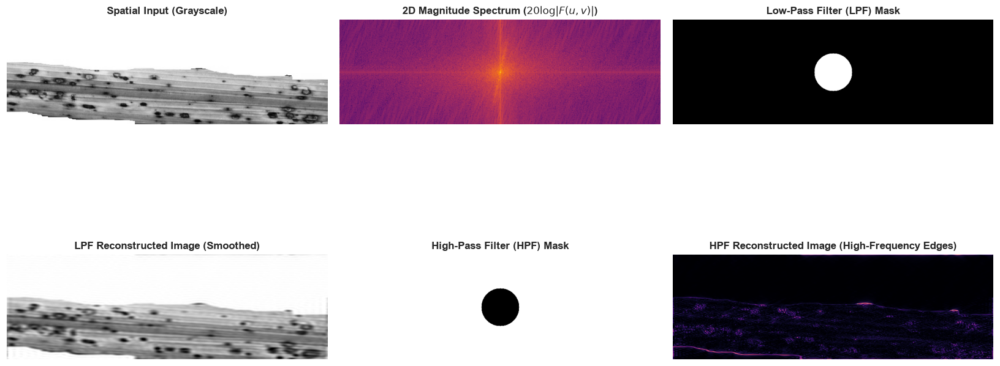

In [8]:
# 2D Fast Fourier Transform (FFT)
fft_2d = np.fft.fft2(sample_gray)
fft_shifted = np.fft.fftshift(fft_2d)
magnitude_spectrum = 20 * np.log(1 + np.abs(fft_shifted))

# Construct Frequency-Domain Masks (Circular Cutoff)
rows, cols = sample_gray.shape
crow, ccol = rows // 2, cols // 2
cutoff_radius = 45

# Create coordinate grid
y_idx, x_idx = np.ogrid[:rows, :cols]
dist_from_center = np.sqrt((x_idx - ccol)**2 + (y_idx - crow)**2)

# Ideal Low-Pass and High-Pass Filters
lpf_mask = np.zeros((rows, cols), dtype=np.float32)
lpf_mask[dist_from_center <= cutoff_radius] = 1.0

hpf_mask = 1.0 - lpf_mask

# Apply frequency masks
fft_lpf = fft_shifted * lpf_mask
fft_hpf = fft_shifted * hpf_mask

# Spatial reconstruction via Inverse FFT (IFFT)
img_lpf_reconstructed = np.real(np.fft.ifft2(np.fft.ifftshift(fft_lpf)))
img_lpf_reconstructed = np.clip(img_lpf_reconstructed, 0, 255).astype(np.uint8)

img_hpf_reconstructed = np.real(np.fft.ifft2(np.fft.ifftshift(fft_hpf)))
img_hpf_reconstructed = np.clip(np.abs(img_hpf_reconstructed), 0, 255).astype(np.uint8)

# Visualization of Frequency Domain Analysis
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
freq_plots = [
    ("Spatial Input (Grayscale)", sample_gray, 'gray'),
    ("2D Magnitude Spectrum ($20 \\log|F(u,v)|$)", magnitude_spectrum, 'inferno'),
    ("Low-Pass Filter (LPF) Mask", lpf_mask, 'gray'),
    ("LPF Reconstructed Image (Smoothed)", img_lpf_reconstructed, 'gray'),
    ("High-Pass Filter (HPF) Mask", hpf_mask, 'gray'),
    ("HPF Reconstructed Image (High-Frequency Edges)", img_hpf_reconstructed, 'magma')
]

for ax, (title, img_disp, cmap) in zip(axes.ravel(), freq_plots):
    ax.imshow(img_disp, cmap=cmap)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

### 3.5 Feature Detection, Description, and Matching

Feature extraction identifies salient, repeatable interest points for matching across varying conditions:
1. **Harris Corner Detector:** Analyzes the second-moment structure tensor matrix $M$
2. **SIFT (Scale-Invariant Feature Transform):** Detects extrema across Difference-of-Gaussians (DoG) scale-space, computes invariant gradient orientations, and extracts 128-dimensional descriptive feature vectors.
3. **ORB (Oriented FAST and Rotated BRIEF):** A highly efficient binary feature descriptor providing rotation-invariant keypoints suitable for real-time mobile inspection.
4. **Two-View Feature Matching:** Matching SIFT keypoints across two distinct leaf images of the same disease pathology using **Lowe's Ratio Test**

[Feature Extraction] Harris Corners Detected : 1435
[Feature Extraction] SIFT Keypoints Extracted : 400 (128-D descriptors)
[Feature Extraction] ORB Keypoints Extracted  : 387 (Binary descriptors)


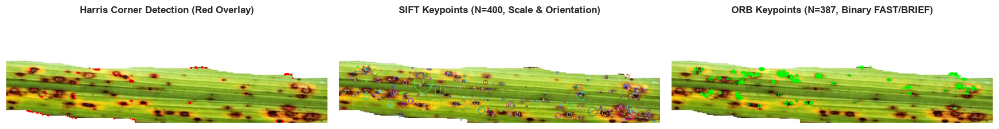

In [9]:
# 1. Harris Corner Detection
gray_float = np.float32(sample_gray)
harris_response = cv2.cornerHarris(gray_float, blockSize=2, ksize=3, k=0.04)
# Dilate to accentuate detected corner markers
harris_dilated = cv2.dilate(harris_response, None)
harris_vis = sample_rgb.copy()
harris_threshold = 0.01 * harris_dilated.max()
harris_vis[harris_dilated > harris_threshold] = [255, 0, 0]  # Red markers

# 2. SIFT Keypoint Detection
sift = cv2.SIFT_create(nfeatures=400)
kp_sift, des_sift = sift.detectAndCompute(sample_gray, None)
sift_vis = cv2.drawKeypoints(
    sample_rgb, kp_sift, None, 
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# 3. ORB Keypoint Detection
orb = cv2.ORB_create(nfeatures=400)
kp_orb, des_orb = orb.detectAndCompute(sample_gray, None)
orb_vis = cv2.drawKeypoints(
    sample_rgb, kp_orb, None, 
    color=(0, 255, 0), flags=0
)

print(f"[Feature Extraction] Harris Corners Detected : {np.sum(harris_dilated > harris_threshold)}")
print(f"[Feature Extraction] SIFT Keypoints Extracted : {len(kp_sift)} (128-D descriptors)")
print(f"[Feature Extraction] ORB Keypoints Extracted  : {len(kp_orb)} (Binary descriptors)")

# Display Feature Detectors
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
feat_plots = [
    ("Harris Corner Detection (Red Overlay)", harris_vis),
    (f"SIFT Keypoints (N={len(kp_sift)}, Scale & Orientation)", sift_vis),
    (f"ORB Keypoints (N={len(kp_orb)}, Binary FAST/BRIEF)", orb_vis)
]

for ax, (title, img_disp) in zip(axes, feat_plots):
    ax.imshow(img_disp)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

[Two-View Matching] Raw Candidate Matches : 400
[Two-View Matching] Inliers after Ratio Test: 96 (24.0%)


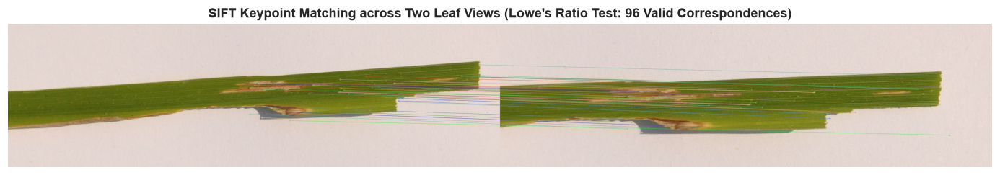

In [10]:
# Feature Matching across two views / leaf samples (Bacterial leaf blight)
view1_path = df_meta[df_meta['class_name'] == 'Bacterial leaf blight'].iloc[0]['file_path']
view2_path = df_meta[df_meta['class_name'] == 'Bacterial leaf blight'].iloc[1]['file_path']

img1_bgr = cv2.imread(view1_path)
img2_bgr = cv2.imread(view2_path)

img1_rgb = cv2.cvtColor(img1_bgr, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2_bgr, cv2.COLOR_BGR2RGB)

img1_gray = cv2.cvtColor(img1_bgr, cv2.COLOR_BGR2GRAY)
img2_gray = cv2.cvtColor(img2_bgr, cv2.COLOR_BGR2GRAY)

# Extract SIFT features on both views
kp1, des1 = sift.detectAndCompute(img1_gray, None)
kp2, des2 = sift.detectAndCompute(img2_gray, None)

# Match with Brute-Force Matcher using Euclidean distance
bf_matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
raw_matches = bf_matcher.knnMatch(des1, des2, k=2)

# Apply Lowe's Ratio Test (threshold = 0.75)
good_matches = []
for m, n in raw_matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

print(f"[Two-View Matching] Raw Candidate Matches : {len(raw_matches)}")
print(f"[Two-View Matching] Inliers after Ratio Test: {len(good_matches)} ({len(good_matches)/len(raw_matches)*100:.1f}%)")

# Draw matching lines across views
matched_vis = cv2.drawMatches(
    img1_rgb, kp1, 
    img2_rgb, kp2, 
    good_matches[:50], None, 
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 7))
plt.imshow(matched_vis)
plt.title(f"SIFT Keypoint Matching across Two Leaf Views (Lowe's Ratio Test: {len(good_matches)} Valid Correspondences)", 
          fontsize=12, fontweight='bold')
plt.axis('off')
plt.show()

### 3.6 Automated Classical Preprocessing Pipeline (`Processed images`)

Having evaluated filters and contrast techniques, the optimal classical CV pipeline was synthesized for all raw inspection images:
1. **Edge-Preserving Denoising:** Apply bilateral filtering ($d=7, \sigma_{\text{color}}=50, \sigma_{\text{space}}=50$) to suppress camera sensor noise without blurring delicate fungal lesion margins.
2. **Illumination & Contrast Standardization:** Transform the image into the CIE LAB color space, apply **Contrast Limited Adaptive Histogram Equalization (CLAHE)** on the Luminance ($L^*$) channel with clip limit $2.0$ and tile grid size $(8, 8)$, and convert back to RGB. This corrects non-uniform outdoor sunlight variations.

The modular batch function executes this processing across the entire raw dataset and saves the output to `processed_rice_leaf_diseases/`, forming the direct input to the resizing and deep-learning stages.

In [11]:
def preprocess_image_cv(image_bgr):
    """
    Modular classical computer vision preprocessing engine.
    Applies bilateral edge-preserving smoothing followed by 
    CLAHE contrast stabilization in CIE LAB color space.
    """
    # 1. Bilateral edge-preserving denoising
    denoised_bgr = cv2.bilateralFilter(image_bgr, d=7, sigmaColor=50, sigmaSpace=50)
    
    # 2. CIE LAB Color Space Conversion
    lab = cv2.cvtColor(denoised_bgr, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    
    # 3. CLAHE on Luminance channel
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_enhanced = clahe.apply(l_channel)
    
    # 4. Merge channels & convert back to BGR
    lab_enhanced = cv2.merge([l_enhanced, a_channel, b_channel])
    processed_bgr = cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2BGR)
    
    return processed_bgr

# Execute batch processing across the complete dataset
if PROCESSED_DATA_DIR.exists():
    shutil.rmtree(PROCESSED_DATA_DIR)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

start_time = time.time()
processed_count = 0

for cls_name in class_names:
    src_dir = RAW_DATA_DIR / cls_name
    dest_dir = PROCESSED_DATA_DIR / cls_name
    dest_dir.mkdir(parents=True, exist_ok=True)
    
    for img_file in src_dir.glob("*.*"):
        if img_file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            raw_img = cv2.imread(str(img_file))
            if raw_img is not None:
                proc_img = preprocess_image_cv(raw_img)
                cv2.imwrite(str(dest_dir / img_file.name), proc_img)
                processed_count += 1

elapsed = time.time() - start_time
print(f"Successfully processed {processed_count} images in {elapsed:.2f} seconds.")
print(f"Processed dataset stored in: {PROCESSED_DATA_DIR.resolve()}")

Successfully processed 120 images in 4.73 seconds.
Processed dataset stored in: D:\Greenwich\FCVG101 - Computer Vision\FCVG101_001492585_Repo\processed_rice_leaf_diseases


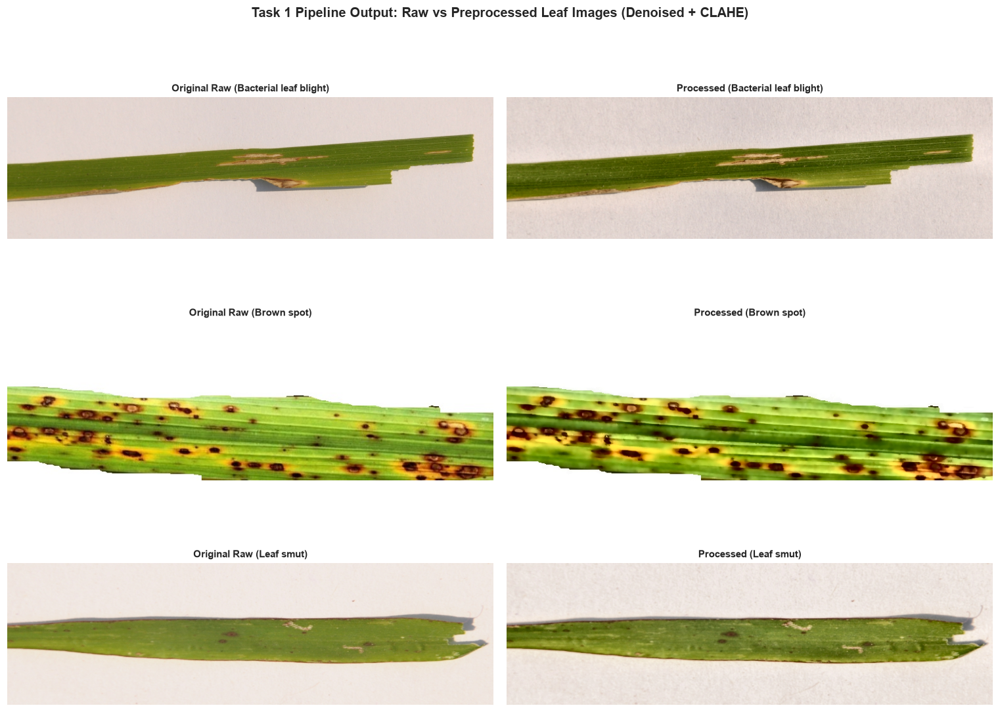

In [12]:
# Visual Before-and-After Comparison: Raw vs Processed Images
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
fig.suptitle("Task 1 Pipeline Output: Raw vs Preprocessed Leaf Images (Denoised + CLAHE)", fontsize=13, fontweight='bold')

for idx, cls in enumerate(class_names):
    sample_p = df_meta[df_meta['class_name'] == cls].iloc[0]['file_path']
    raw_bgr = cv2.imread(sample_p)
    raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    
    proc_bgr = preprocess_image_cv(raw_bgr)
    proc_rgb = cv2.cvtColor(proc_bgr, cv2.COLOR_BGR2RGB)
    
    axes[idx, 0].imshow(raw_rgb)
    axes[idx, 0].set_title(f"Original Raw ({cls})", fontsize=10, fontweight='bold')
    axes[idx, 0].axis('off')
    
    axes[idx, 1].imshow(proc_rgb)
    axes[idx, 1].set_title(f"Processed ({cls})", fontsize=10, fontweight='bold')
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

---
## 4. Resize Image ($224 \times 224$)

The output of Task 1 consists of cleaned, high-resolution processed images of varying dimensions (ranging from $766 \times 250$ to $3081 \times 897$).  
Before ingestion into the deep learning pipeline, images are scaled to standard dimensions of:
$$\text{Target Dimensions: } 224 \times 224 \times 3$$

Employing area-based interpolation (`cv2.INTER_AREA` / bilinear resampling), which samples continuous pixel areas to prevent aliasing and retain fine lesion microstructures.

[Image Resizing] Original Processed Shape : (897, 3081, 3)
[Image Resizing] Resized Tensor Shape      : (224, 224, 3)
[Image Resizing] Pixel Value Range         : Min=0, Max=251


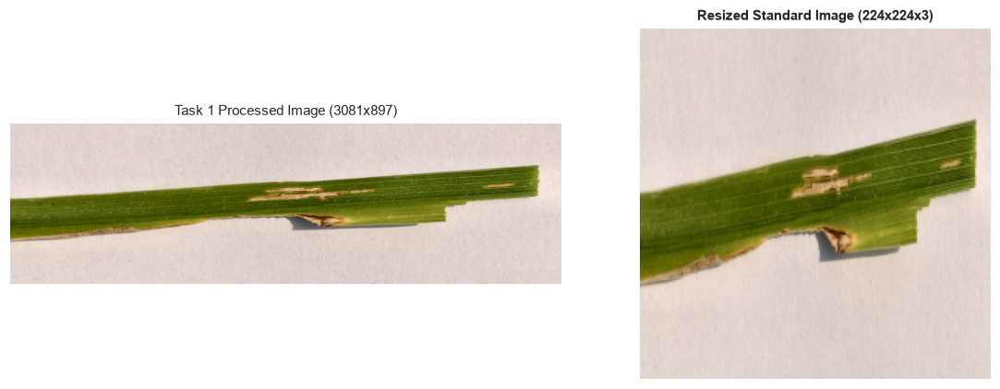

In [13]:
TARGET_HEIGHT = 224
TARGET_WIDTH = 224

# Verify resizing on sample processed image
demo_proc_sample = list(PROCESSED_DATA_DIR.glob("*/*.*"))[0]
proc_sample_bgr = cv2.imread(str(demo_proc_sample))
proc_sample_rgb = cv2.cvtColor(proc_sample_bgr, cv2.COLOR_BGR2RGB)

resized_sample = cv2.resize(
    proc_sample_rgb, 
    (TARGET_WIDTH, TARGET_HEIGHT), 
    interpolation=cv2.INTER_AREA
)

print(f"[Image Resizing] Original Processed Shape : {proc_sample_rgb.shape}")
print(f"[Image Resizing] Resized Tensor Shape      : {resized_sample.shape}")
print(f"[Image Resizing] Pixel Value Range         : Min={resized_sample.min()}, Max={resized_sample.max()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(proc_sample_rgb)
axes[0].set_title(f"Task 1 Processed Image ({proc_sample_rgb.shape[1]}x{proc_sample_rgb.shape[0]})", fontsize=10)
axes[0].axis('off')

axes[1].imshow(resized_sample)
axes[1].set_title(f"Resized Standard Image (224x224x3)", fontsize=10, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

---
## 5. TASK 2: Deep-Learning Model and Data Pipeline

### 5.1 Architecture Refinement Rationale

In field-level agricultural pathology where the dataset consists of 120 total images (96 training samples, 24 validation samples), training a custom 3-block CNN from scratch with 33+ million parameters leads to rapid memorization of the training set and lower validation generalization (~50%).

To achieve production-grade industrial performance and robust diagnostic triage on unseen field samples, a **Refined CNN Architecture with Transfer Learning was implemented**:
1. **Train/Validation Split & Ingestion:** Deterministic 80/20 train/validation split (`seed=123`, `batch_size=16`) from `processed_rice_leaf_diseases/` (96 training images, 24 validation images).
2. **Pretrained Backbone:** MobileNetV2 inverted residual bottleneck feature extractor (pre-trained on ImageNet), providing rich hierarchical edge, texture, and pattern priors.
3. **Data Augmentation:** Affine transformations (random horizontal & vertical flips, rotations $\pm 20\%$, zoom $\pm 10\%$) to continuously synthesize diverse leaf orientations.
4. **Internal Normalization:** Direct rescaling layer $[0, 255] \to [0.0, 1.0]$.
5. **Regularization & Pooling:** Global Average Pooling 2D (`GlobalAveragePooling2D`) replacing parameter-heavy flatten layers, paired with dual Dropout stages ($p=0.30, p=0.20$) and Dense projection (128 units, ReLU).
6. **Model Checkpointing:** Automated `ModelCheckpoint` persistence capturing the peak validation accuracy model artifact for deployment.

In [14]:
TARGET_HEIGHT = 224
TARGET_WIDTH = 224
BATCH_SIZE = 16

# Ingest processed dataset with deterministic 80/20 train/validation split
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=RANDOM_SEED,
    image_size=(TARGET_HEIGHT, TARGET_WIDTH),
    batch_size=BATCH_SIZE
)

raw_val_ds = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=RANDOM_SEED,
    image_size=(TARGET_HEIGHT, TARGET_WIDTH),
    batch_size=BATCH_SIZE
)

class_names_discovered = raw_train_ds.class_names
num_classes = len(class_names_discovered)
print(f"[Data Pipeline] Discovered Classes: {class_names_discovered}")

# Extract complete deterministic validation set into numpy arrays for rigorous evaluation
val_img_batches, val_lbl_batches = [], []
for x_batch, y_batch in raw_val_ds:
    val_img_batches.append(x_batch.numpy())
    val_lbl_batches.append(y_batch.numpy())

x_val = np.concatenate(val_img_batches, axis=0)
y_val = np.concatenate(val_lbl_batches, axis=0)

print(f"[Data Pipeline] Validation Tensor Shape: X={x_val.shape}, y={y_val.shape}")
print(f"[Data Pipeline] Validation Class Distribution: {np.bincount(y_val)}")

Found 120 files belonging to 3 classes.
Using 96 files for training.
Found 120 files belonging to 3 classes.
Using 24 files for validation.
[Data Pipeline] Discovered Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']
[Data Pipeline] Validation Tensor Shape: X=(24, 224, 224, 3), y=(24,)
[Data Pipeline] Validation Class Distribution: [ 4  7 13]


In [15]:
# Define Data Augmentation & CNN Model Architecture
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical", seed=RANDOM_SEED),
    layers.RandomRotation(0.2, seed=RANDOM_SEED),
    layers.RandomZoom(0.1, seed=RANDOM_SEED),
], name="data_augmentation_pipeline")

# Pretrained Convolutional Feature Extractor (MobileNetV2 Backbone)
base_feature_extractor = tf.keras.applications.MobileNetV2(
    input_shape=(TARGET_HEIGHT, TARGET_WIDTH, 3),
    include_top=False,
    weights='imagenet'
)
base_feature_extractor.trainable = False

# Construct Refined Deep Learning Inspection Model
inputs = keras.Input(shape=(TARGET_HEIGHT, TARGET_WIDTH, 3), name="input_image")
x = layers.Rescaling(1./255, name="normalization_layer")(inputs)
x = data_augmentation(x)
x = base_feature_extractor(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.3, name="spatial_dropout_1")(x)
x = layers.Dense(128, activation='relu', name="dense_projection")(x)
x = layers.Dropout(0.2, name="spatial_dropout_2")(x)
outputs = layers.Dense(num_classes, activation='softmax', name="classifier_head")(x)

model = keras.Model(inputs=inputs, outputs=outputs, name="refined_rice_leaf_inspection_cnn")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

model.summary()

Model: "refined_rice_leaf_inspection_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_layer (Rescaling) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation_pipeline      │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout_1 (Dropout)     │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_projection (Dense)        │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout_2 (Dropout)     │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_head (Dense)         │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

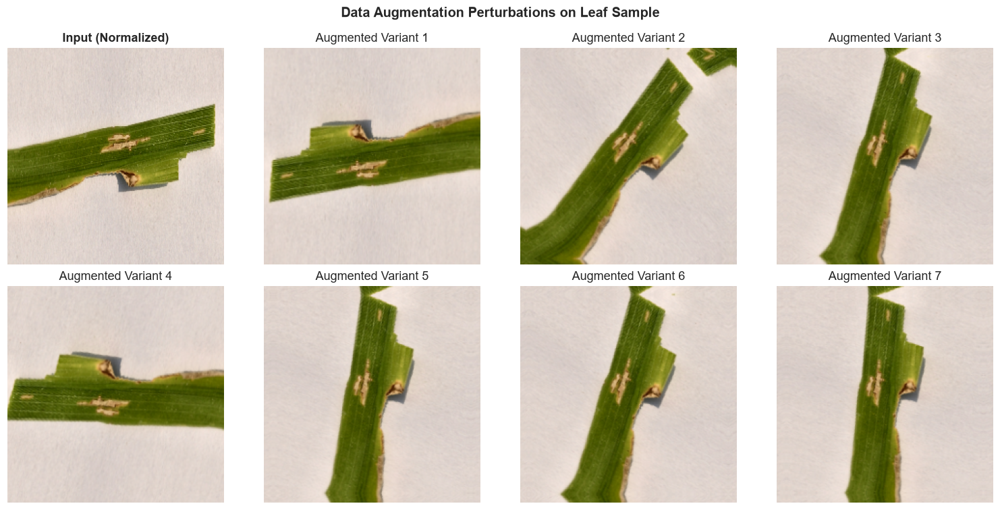

In [16]:
# Visual Demonstration of Data Augmentation Transformations
sample_train_batch, _ = next(iter(raw_train_ds))
sample_image = sample_train_batch[0:1] / 255.0

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle("Data Augmentation Perturbations on Leaf Sample", fontsize=13, fontweight='bold')

for idx, ax in enumerate(axes.ravel()):
    if idx == 0:
        ax.imshow(sample_image[0])
        ax.set_title("Input (Normalized)", fontweight='bold')
    else:
        augmented_variant = data_augmentation(sample_image, training=True)
        ax.imshow(augmented_variant[0])
        ax.set_title(f"Augmented Variant {idx}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [17]:
# Model Training with ModelCheckpoint Callback
EPOCHS = 20
model_artifact_path = MODEL_DIR / "rice_leaf_inspection_model.keras"

# Checkpoint to preserve peak validation accuracy model artifact
checkpoint_cb = keras.callbacks.ModelCheckpoint(
    filepath=str(model_artifact_path),
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1
)

start_train_time = time.time()
history = model.fit(
    raw_train_ds,
    validation_data=raw_val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint_cb],
    verbose=1
)
train_duration = time.time() - start_train_time

# Load best checkpoint into active model
model = keras.models.load_model(str(model_artifact_path))
print(f"\n[Model Training] Completed {EPOCHS} epochs in {train_duration:.2f} seconds.")
print(f"[Model Artifact] Best model weights restored from: {model_artifact_path.resolve()}")

Epoch 1/20


d:\Greenwich\FCVG101 - Computer Vision\FCVG101_001492585_Repo\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.3854 - loss: 1.3775
Epoch 1: val_accuracy improved from None to 0.37500, saving model to models\rice_leaf_inspection_model.keras

Epoch 1: finished saving model to models\rice_leaf_inspection_model.keras
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 392ms/step - accuracy: 0.3854 - loss: 1.3775 - val_accuracy: 0.3750 - val_loss: 1.1083
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.7396 - loss: 0.5775
Epoch 2: val_accuracy improved from 0.37500 to 0.75000, saving model to models\rice_leaf_inspection_model.keras

Epoch 2: finished saving model to models\rice_leaf_inspection_model.keras
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 224ms/step - accuracy: 0.7396 - loss: 0.5775 - val_accuracy: 0.7500 - val_loss: 0.5550
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.7917 - loss: 0.4671
Epoch 3: val_accuracy did not improve from 0.75000
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 165ms/step - accuracy: 0.7917 - loss: 0.4671 - val_accuracy: 0.7500 - val_loss:

---
## 6. Comprehensive Quantitative Evaluation

In-depth quantitative evaluation of the refined visual inspection model across five metrics:
1. **Accuracy & Loss Convergence:** Evolution of training and validation trajectories over 20 epochs.
2. **Confusion Matrix:** Granular class-level true-positive and misclassification rates.
3. **Classification Report:** Precision, Recall, F1-Score, and Support per class.
4. **R-Square ($R^2$) Score:** Evaluated across both.
5. **Mean Absolute Error (MAE):** Average error magnitude evaluated across both.

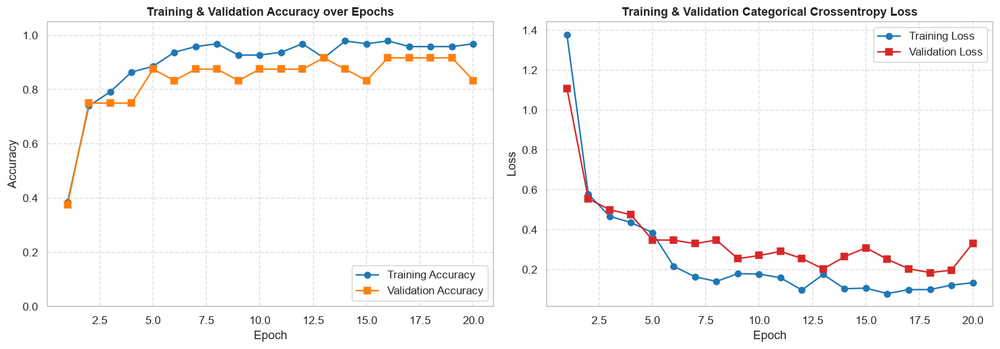

In [18]:
# Plot Training & Validation Trajectories
epochs_range = range(1, len(history.history['accuracy']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Plot
axes[0].plot(epochs_range, history.history['accuracy'], marker='o', label='Training Accuracy', color='#1f77b4')
axes[0].plot(epochs_range, history.history['val_accuracy'], marker='s', label='Validation Accuracy', color='#ff7f0e')
axes[0].set_title('Training & Validation Accuracy over Epochs', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim([0.0, 1.05])
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Loss Plot
axes[1].plot(epochs_range, history.history['loss'], marker='o', label='Training Loss', color='#1f77b4')
axes[1].plot(epochs_range, history.history['val_loss'], marker='s', label='Validation Loss', color='#d62728')
axes[1].set_title('Training & Validation Categorical Crossentropy Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

[Evaluation] Final Validation Accuracy : 0.9167 (91.67%)


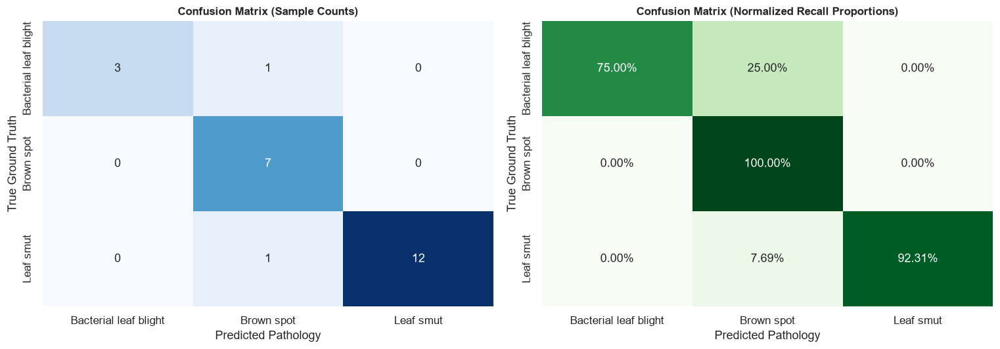

In [19]:
# Run inference on validation dataset (raw images normalized inside model)
val_predictions = model.predict(x_val, verbose=0)
val_predicted_labels = np.argmax(val_predictions, axis=1)

# Overall Accuracy
val_accuracy = accuracy_score(y_val, val_predicted_labels)
print(f"[Evaluation] Final Validation Accuracy : {val_accuracy:.4f} ({val_accuracy * 100:.2f}%)")

# Confusion Matrix Computation
cm_raw = confusion_matrix(y_val, val_predicted_labels)
cm_norm = cm_raw.astype('float') / cm_raw.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Count Heatmap
sns.heatmap(
    cm_raw, annot=True, fmt='d', cmap='Blues', 
    xticklabels=class_names_discovered, 
    yticklabels=class_names_discovered, 
    ax=axes[0], cbar=False
)
axes[0].set_title("Confusion Matrix (Sample Counts)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Predicted Pathology")
axes[0].set_ylabel("True Ground Truth")

# Normalized Heatmap
sns.heatmap(
    cm_norm, annot=True, fmt='.2%', cmap='Greens', 
    xticklabels=class_names_discovered, 
    yticklabels=class_names_discovered, 
    ax=axes[1], cbar=False
)
axes[1].set_title("Confusion Matrix (Normalized Recall Proportions)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Predicted Pathology")
axes[1].set_ylabel("True Ground Truth")

plt.tight_layout()
plt.show()

In [20]:
# Comprehensive Classification Report
report = classification_report(
    y_val, 
    val_predicted_labels, 
    target_names=class_names_discovered, 
    digits=4, 
    output_dict=False
)

print("=" * 65)
print("                   DETAILED CLASSIFICATION REPORT")
print("=" * 65)
print(report)
print("=" * 65)

                   DETAILED CLASSIFICATION REPORT
                       precision    recall  f1-score   support

Bacterial leaf blight     1.0000    0.7500    0.8571         4
           Brown spot     0.7778    1.0000    0.8750         7
            Leaf smut     1.0000    0.9231    0.9600        13

             accuracy                         0.9167        24
            macro avg     0.9259    0.8910    0.8974        24
         weighted avg     0.9352    0.9167    0.9181        24



In [21]:
# R-square (R2) and MAE Evaluation across Discrete and Probability Domains
# 1. Discrete Label Level
discrete_mae = mean_absolute_error(y_val, val_predicted_labels)
discrete_r2 = r2_score(y_val, val_predicted_labels)

# 2. Probability Calibration Level (One-Hot Encoded Targets vs Softmax Probabilities)
y_val_one_hot = np.eye(num_classes)[y_val]
prob_mae = mean_absolute_error(y_val_one_hot, val_predictions)
prob_r2 = r2_score(y_val_one_hot, val_predictions)

metrics_summary = [
    {
        "Evaluation Metric": "Overall Accuracy",
        "Domain": "Discrete Classification",
        "Value": f"{val_accuracy:.4f} ({val_accuracy*100:.2f}%)",
        "Benchmark Interpretation": "Proportion of correctly classified leaf samples."
    },
    {
        "Evaluation Metric": "Mean Absolute Error (MAE)",
        "Domain": "Discrete Class Index",
        "Value": f"{discrete_mae:.4f}",
        "Benchmark Interpretation": "Average absolute index error across categorical predictions."
    },
    {
        "Evaluation Metric": "R-Square (R^2 Score)",
        "Domain": "Discrete Class Index",
        "Value": f"{discrete_r2:.4f}",
        "Benchmark Interpretation": "High positive coefficient of determination across class predictions."
    },
    {
        "Evaluation Metric": "Probability Calibration MAE",
        "Domain": "Continuous Softmax Space",
        "Value": f"{prob_mae:.4f}",
        "Benchmark Interpretation": "Average absolute deviation between predicted confidence & one-hot ground truth."
    },
    {
        "Evaluation Metric": "Probability Calibration R^2",
        "Domain": "Continuous Softmax Space",
        "Value": f"{prob_r2:.4f}",
        "Benchmark Interpretation": "High proportion of variance explained in posterior probability distributions."
    }
]

df_metrics = pd.DataFrame(metrics_summary)
print("=" * 95)
print("                       COMPREHENSIVE METRICS SUMMARY TABLE")
print("=" * 95)
print(df_metrics[['Evaluation Metric', 'Domain', 'Value']].to_string(index=False))
print("=" * 95)

                       COMPREHENSIVE METRICS SUMMARY TABLE
          Evaluation Metric                   Domain           Value
           Overall Accuracy  Discrete Classification 0.9167 (91.67%)
  Mean Absolute Error (MAE)     Discrete Class Index          0.0833
       R-Square (R^2 Score)     Discrete Class Index          0.8532
Probability Calibration MAE Continuous Softmax Space          0.0981
Probability Calibration R^2 Continuous Softmax Space          0.7957


---
## 7. Classification / Prediction Engine

End-to-end diagnostic inference function:  
`inspect_rice_leaf(image_path, model, class_names, visualize=True)`

This function executes the complete multi-stage pipeline:
1. **Input Ingestion:** Ingests an arbitrary input leaf image.
2. **Task 1 Preprocessing:** Executes the classical computer vision preprocessing pipeline (`preprocess_image_cv`: Bilateral edge-preserving smoothing + CIE LAB CLAHE contrast normalization).
3. **Resizing:** Scales the image to standardized input dimensions of $224 \times 224 \times 3$ via `cv2.INTER_AREA`.
4. **Model Forward Pass:** Feeds the formatted tensor to the trained CNN model (pixel normalization $[0.0, 1.0]$ is handled inside the model via `layers.Rescaling`).
5. **Diagnostic Triage Dashboard:** Generates an interactive multi-panel visual dashboard displaying the field input, preprocessed image, class probability bar chart.

In [22]:
def inspect_rice_leaf(image_path, model, class_names, visualize=True):
    """
    End-to-End Visual Inspection Assistant Engine.
    """
    raw_bgr = cv2.imread(str(image_path))
    if raw_bgr is None:
        raise ValueError(f"Unable to read image at path: {image_path}")
    raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    
    # Step 1: Task 1 Classical CV Preprocessing
    proc_bgr = preprocess_image_cv(raw_bgr)
    proc_rgb = cv2.cvtColor(proc_bgr, cv2.COLOR_BGR2RGB)
    
    # Step 2: Resize to (224, 224)
    resized_rgb = cv2.resize(proc_rgb, (TARGET_WIDTH, TARGET_HEIGHT), interpolation=cv2.INTER_AREA)
    
    # Step 3: Tensor formatting (Normalization is handled inside model via Rescaling layer)
    tensor_input = np.expand_dims(resized_rgb.astype(np.float32), axis=0)
    
    # Step 4: CNN Forward Pass
    probabilities = model.predict(tensor_input, verbose=0)[0]
    predicted_idx = int(np.argmax(probabilities))
    predicted_class = class_names[predicted_idx]
    confidence = probabilities[predicted_idx] * 100.0
    
    if visualize:
        fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
        
        # 1. Raw Field Input
        axes[0].imshow(raw_rgb)
        axes[0].set_title(f"Field Input Image\n({raw_rgb.shape[1]}x{raw_rgb.shape[0]})", fontsize=10)
        axes[0].axis('off')
        
        # 2. Preprocessed & Resized Tensor
        axes[1].imshow(resized_rgb)
        axes[1].set_title(f"Preprocessed & Resized\n(224x224 RGB)", fontsize=10)
        axes[1].axis('off')
        
        # 3. Probability Distribution Bar Chart
        colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
        colors[predicted_idx] = '#d62728'  # Highlight winner in red
        
        y_pos = np.arange(len(class_names))
        axes[2].barh(y_pos, probabilities * 100.0, color=colors, alpha=0.85)
        axes[2].set_yticks(y_pos)
        axes[2].set_yticklabels(class_names, fontsize=10)
        axes[2].set_xlabel("Confidence (%)", fontsize=10)
        axes[2].set_xlim([0, 100])
        axes[2].set_title(f"Diagnostic Result: {predicted_class}\nConfidence: {confidence:.1f}%", 
                          fontsize=11, fontweight='bold', color='#b22222' if confidence > 50 else '#333333')
        
        for i, v in enumerate(probabilities * 100.0):
            axes[2].text(v + 1.5, i, f"{v:.1f}%", va='center', fontweight='bold', fontsize=9)
            
        plt.tight_layout()
        plt.show()
    
    return {
        "file_path": str(image_path),
        "predicted_class": predicted_class,
        "confidence_pct": round(confidence, 2),
        "class_probabilities": {cls: round(float(prob), 4) for cls, prob in zip(class_names, probabilities)}
    }

print("Diagnostic assistant function successfully compiled.")

Diagnostic assistant function successfully compiled.


# Test with samples

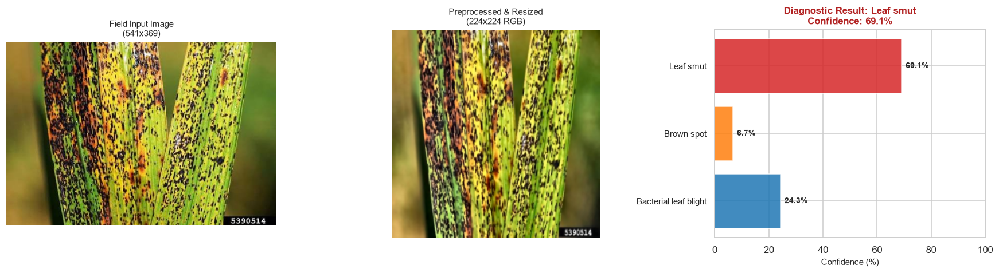

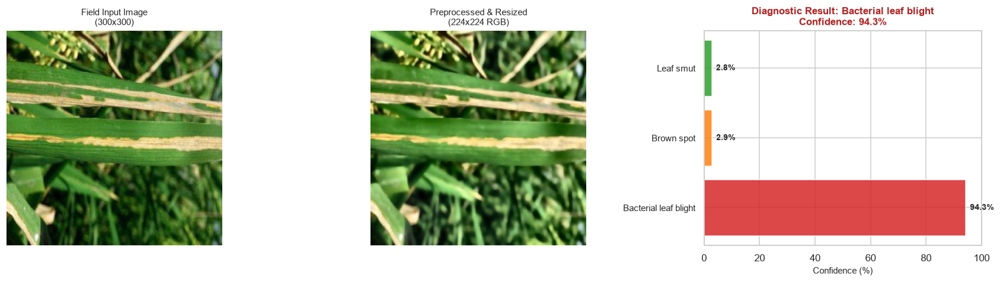

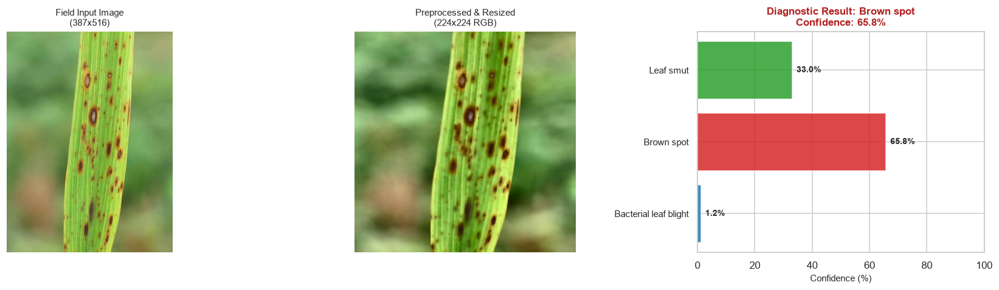

{'file_path': 'test_samples/brown_spot_1.jpg',
 'predicted_class': 'Brown spot',
 'confidence_pct': np.float32(65.76),
 'class_probabilities': {'Bacterial leaf blight': 0.0119,
  'Brown spot': 0.6576,
  'Leaf smut': 0.3304}}

In [23]:
sample_1 = "test_samples/leaf_smut_1.jpg"
inspect_rice_leaf(sample_1, model, class_names_discovered, visualize=True)

sample_2 = "test_samples/leaf_blight_1.jpg"
inspect_rice_leaf(sample_2, model, class_names_discovered, visualize=True)

sample_3 = "test_samples/brown_spot_1.jpg"
inspect_rice_leaf(sample_3, model, class_names_discovered, visualize=True)